In [11]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import SGDRegressor , LinearRegression
from sklearn.preprocessing import PolynomialFeatures

from mpl_toolkits.mplot3d import Axes3D
import torch
import torch.nn as nn
import torch.optim as optim

plt.style.use('dark_background')
np.random.seed(42)
torch.manual_seed(42)




In [12]:
clifornia = fetch_california_housing()
x = clifornia.data
y = clifornia.target
feature_names = clifornia.feature_names
feature_names


['MedInc',
 'HouseAge',
 'AveRooms',
 'AveBedrms',
 'Population',
 'AveOccup',
 'Latitude',
 'Longitude']

In [13]:
print('First 5 Samples: \n')
for i in range(5):
    print(f"The House {i+1}: ")

    for j,name in enumerate(feature_names):
      print(f"{name} : {x[i,j]:.2f}")

    print(f"Price: {y[i] * 100000 :,.0f}")
    print("_______________")




First 5 Samples: 

The House 1: 
MedInc : 8.33
HouseAge : 41.00
AveRooms : 6.98
AveBedrms : 1.02
Population : 322.00
AveOccup : 2.56
Latitude : 37.88
Longitude : -122.23
Price: 452,600
_______________
The House 2: 
MedInc : 8.30
HouseAge : 21.00
AveRooms : 6.24
AveBedrms : 0.97
Population : 2401.00
AveOccup : 2.11
Latitude : 37.86
Longitude : -122.22
Price: 358,500
_______________
The House 3: 
MedInc : 7.26
HouseAge : 52.00
AveRooms : 8.29
AveBedrms : 1.07
Population : 496.00
AveOccup : 2.80
Latitude : 37.85
Longitude : -122.24
Price: 352,100
_______________
The House 4: 
MedInc : 5.64
HouseAge : 52.00
AveRooms : 5.82
AveBedrms : 1.07
Population : 558.00
AveOccup : 2.55
Latitude : 37.85
Longitude : -122.25
Price: 341,300
_______________
The House 5: 
MedInc : 3.85
HouseAge : 52.00
AveRooms : 6.28
AveBedrms : 1.08
Population : 565.00
AveOccup : 2.18
Latitude : 37.85
Longitude : -122.25
Price: 342,200
_______________


In [14]:
# Basic Statistics
print(f"{'Feature':<15} {'Mean':<12} {"Std":<12} {'Min':<12} {"Max":<12}")
print("="*61,"\n")

for i,name in enumerate(feature_names):
  print(f"{name:<15}  {np.mean(x[:,i]):<12.2f} {np.std(x[:,i]):<12.2f} {np.min(x[:,i]):<12.2f} {np.max(x[:,i]):<12.2f}")
  print(" "*61)

print(f" \n{'Price':<15}  {np.mean(y):<12.2f} {np.std(y):<12.2f} {np.min(y):<12.2f} {np.max(y):<12.2f}")


Feature         Mean         Std          Min          Max         

MedInc           3.87         1.90         0.50         15.00       
                                                             
HouseAge         28.64        12.59        1.00         52.00       
                                                             
AveRooms         5.43         2.47         0.85         141.91      
                                                             
AveBedrms        1.10         0.47         0.33         34.07       
                                                             
Population       1425.48      1132.43      3.00         35682.00    
                                                             
AveOccup         3.07         10.39        0.69         1243.33     
                                                             
Latitude         35.63        2.14         32.54        41.95       
                                                             
Longitude     

In [15]:
df=pd.DataFrame(x,columns=feature_names)
df['Price']=y
corr=df.corr()
corr

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Price
MedInc,1.000000,-0.119034,0.326895,-0.062040,0.004834,0.018766,-0.079809,-0.015176,0.688075
HouseAge,-0.119034,1.000000,-0.153277,-0.077747,-0.296244,0.013191,0.011173,-0.108197,0.105623
AveRooms,0.326895,-0.153277,1.000000,0.847621,-0.072213,-0.004852,0.106389,-0.027540,0.151948
AveBedrms,-0.062040,-0.077747,0.847621,1.000000,-0.066197,-0.006181,0.069721,0.013344,-0.046701
Population,0.004834,-0.296244,-0.072213,-0.066197,1.000000,0.069863,-0.108785,0.099773,-0.024650
AveOccup,0.018766,0.013191,-0.004852,-0.006181,0.069863,1.000000,0.002366,0.002476,-0.023737
Latitude,-0.079809,0.011173,0.106389,0.069721,-0.108785,0.002366,1.000000,-0.924664,-0.144160
Longitude,-0.015176,-0.108197,-0.027540,0.013344,0.099773,0.002476,-0.924664,1.000000,-0.045967
Price,0.688075,0.105623,0.151948,-0.046701,-0.024650,-0.023737,-0.144160,-0.045967,1.000000


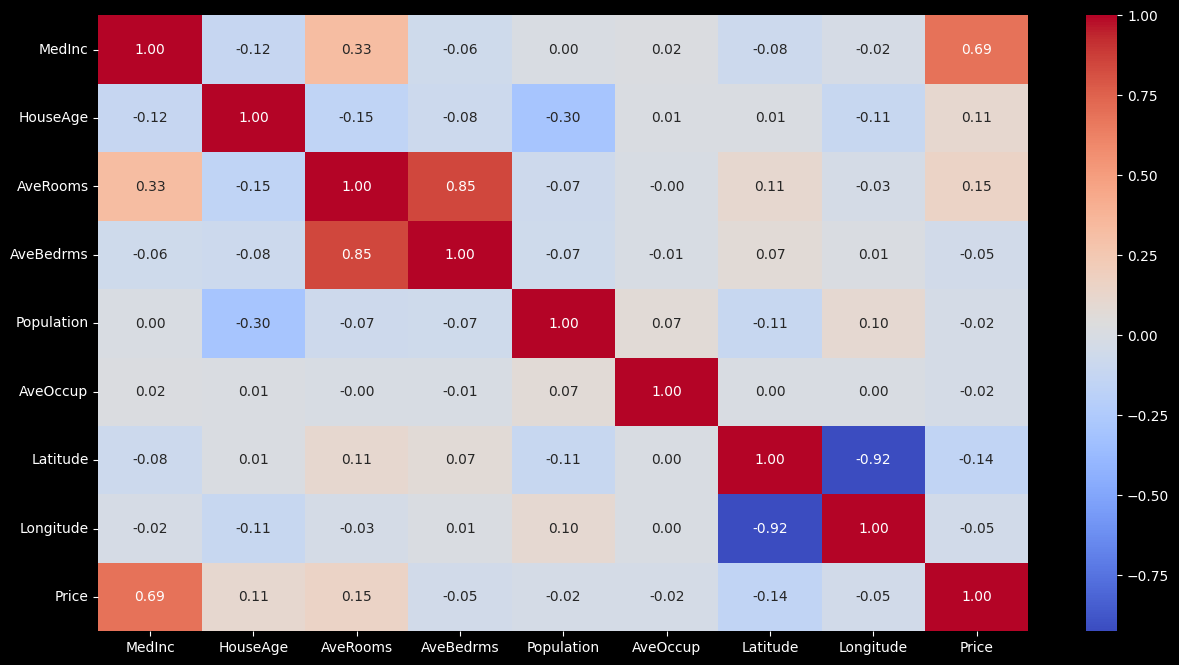

In [16]:
plt.figure(figsize=(15,8))
sns.heatmap(corr , annot=True , fmt='.2f' , cmap='coolwarm')
plt.show()

#Build A LinearRegression Model From Scrath

In [17]:
x_medincome=x[:,0]
y_price = y

np.random.seed(42)

w = np.random.rand()
b = np.random.rand()

learning_rate = 0.01
iteration = 1000
n=len(x_medincome)

csotval_list=np.zeros(iteration)


for i in range(iteration):
  y_pred = w * x_medincome + b
  error = y_pred - y_price

  grad_w=np.mean(error * x_medincome)
  grad_b=np.mean(error)



  w = w - (learning_rate * grad_w)
  b = b - (learning_rate * grad_b)

  csotval_list[i] = np.mean(error**2)
  if csotval_list[i] < 1e-5 :
    break




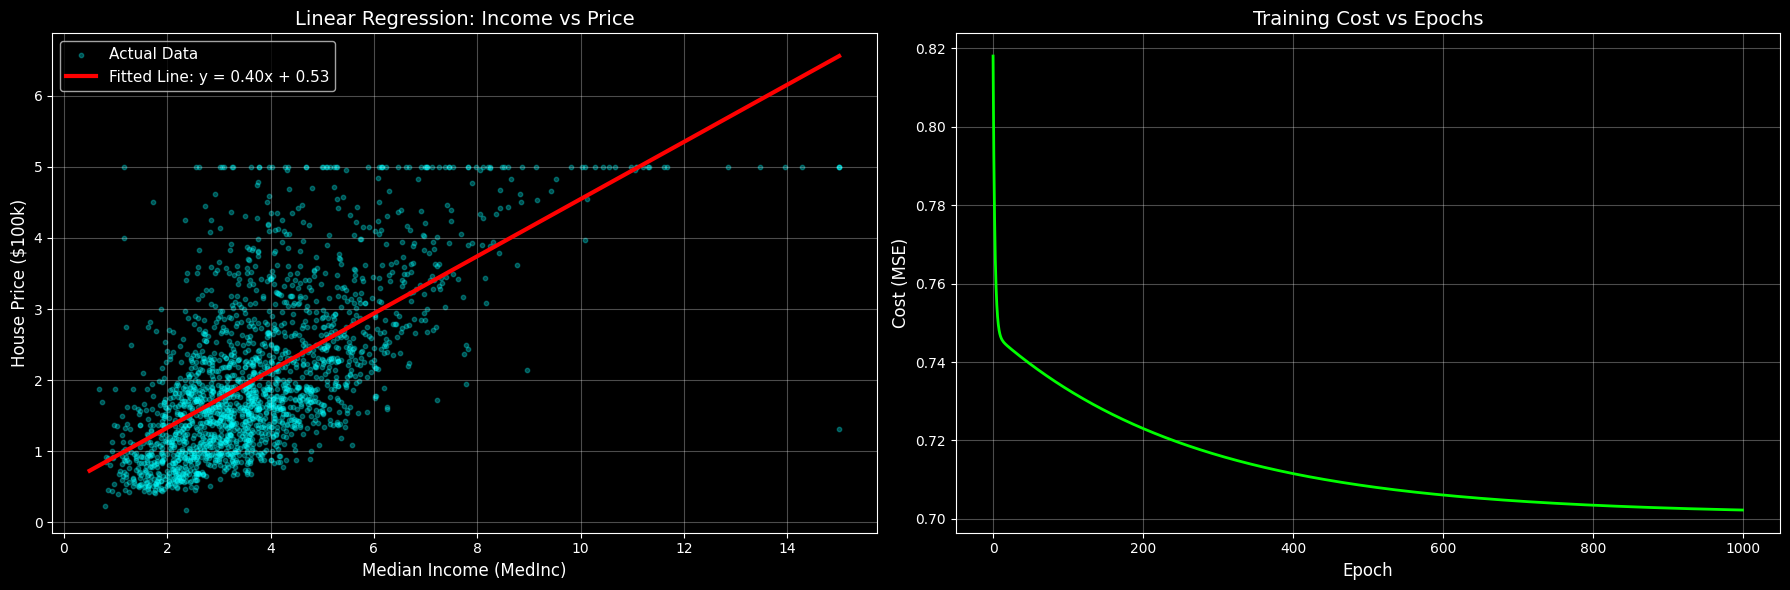


Notice how the cost decreases smoothly - this is gradient descent working!
The red line shows our model's predictions.


In [18]:
# Visualize the results
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Plot 1: Data and fitted line
ax1 = axes[0]

# Sample points for clearer visualization
indices = np.random.choice(n, 2000, replace=False)
ax1.scatter(x_medincome[indices], y_price[indices], alpha=0.3, s=10,c='cyan', label='Actual Data')

# Plot fitted line
x_line = np.linspace(x_medincome.min(), x_medincome.max(), 100)
y_line = w * x_line + b
ax1.plot(x_line, y_line, 'r-', linewidth=3, label=f'Fitted Line: y = {w:.2f}x + {b:.2f}')

ax1.set_xlabel('Median Income (MedInc)', fontsize=12)
ax1.set_ylabel('House Price ($100k)', fontsize=12)
ax1.set_title('Linear Regression: Income vs Price', fontsize=14)
ax1.legend(fontsize=11)
ax1.grid(True, alpha=0.3)

# Plot 2: Cost convergence
ax2 = axes[1]
ax2.plot(csotval_list, 'lime', linewidth=2)
ax2.set_xlabel('Epoch', fontsize=12)
ax2.set_ylabel('Cost (MSE)', fontsize=12)
ax2.set_title('Training Cost vs Epochs', fontsize=14)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nNotice how the cost decreases smoothly - this is gradient descent working!")
print("The red line shows our model's predictions.")

In [19]:
def create_polynomial_features(x, degree):


    n = len(x)
    X_poly = np.zeros((n, degree + 1))

    for i in range(degree + 1):
        X_poly[:, i] = x ** i

    return X_poly


test_x = np.array([1, 2, 3]) # this is the column of x
test_poly = create_polynomial_features(test_x, degree=2)

test_poly

array([[1., 1., 1.],
       [1., 2., 4.],
       [1., 3., 9.]])

In [20]:

def train_polynomial_regression_sklearn(x, y, degree, epochs=500):

    from sklearn.preprocessing import PolynomialFeatures
    from sklearn.linear_model import LinearRegression


    poly = PolynomialFeatures(degree=degree, include_bias=True)
    X_poly = poly.fit_transform(x.reshape(-1, 1))


    model = LinearRegression(fit_intercept=False)
    model.fit(X_poly, y)


    y_pred = model.predict(X_poly)
    mse = 0.5 * np.mean((y_pred - y)**2)


    costs = [mse] * epochs

    return model.coef_, costs, X_poly

In [21]:
degrees = [1, 2, 3, 5]
models = {}

print("Training polynomial models with sklearn...\n")
for degree in degrees:
    weights, costs, _ = train_polynomial_regression_sklearn(x_medincome, y_price,
                                                            degree=degree,
                                                            epochs=500)
    models[degree] = (weights, costs)

Training polynomial models with sklearn...



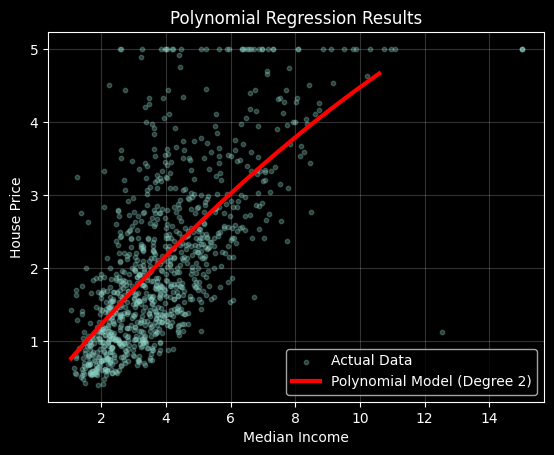

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures

degree = 2   # نفس الدرجة اللي دربت عليها

# اختيار 1000 نقطة فقط من البيانات للرسم
indices = np.random.choice(len(x_medincome), 1000, replace=False)

# إنشاء قيم مرتبة للرسم
x_plot = np.linspace(
    np.percentile(x_medincome, 1),
    np.percentile(x_medincome, 99),
    200
)

# إنشاء Polynomial Features
poly = PolynomialFeatures(degree=degree, include_bias=True)
X_plot = poly.fit_transform(x_plot.reshape(-1, 1))

# الحصول على أوزان الموديل
weights = models[degree][0]

# حساب توقعات الموديل
y_plot = X_plot @ weights

# رسم عينة من البيانات فقط
plt.scatter(
    x_medincome[indices],
    y_price[indices],
    alpha=0.3,
    s=10,
    label="Actual Data"
)

# رسم الموديل باللون الأحمر
plt.plot(
    x_plot,
    y_plot,
    color="red",
    linewidth=3,
    label=f"Polynomial Model (Degree {degree})"
)

plt.xlabel("Median Income")
plt.ylabel("House Price")
plt.title("Polynomial Regression Results")
plt.legend()
plt.grid(alpha=0.2)
plt.show()